# 11 · Partial checks that escalate, and full checks (v1.4)

When a SmartShop shopper scans the till barcode to pay, the till can ask for one of two checks,
and a colleague carries it out:

- **Partial check:** the colleague checks a sample of the basket, about 20–25% of the items (at
  least 2). **If anything is unscanned, the check device suggests a full check** of the whole basket.
- **Full check:** every item, straight away.

Up to v1.3 the project modelled a partial check as a fixed 3 items that stopped there, whatever
the basket size. v1.4 models it as above, recalibrated so partial checks still find something about
as often as published research reports (2.88% of audits, ECR; simulated 3.0%).

Two questions:

1. How much does modelling today's checks properly change the comparison?
2. When the till targets a shopper, should it ask for a partial check (cheaper, so more shoppers
   can be checked) or a full check? The share of risk-based checks that are full is chosen on the
   tuning period, at today's colleague time and on a half-staffed shift.

Produced by `python -m smartshop.reporting.checks`; this notebook reads its outputs.

In [1]:
import json

import matplotlib.pyplot as plt
import pandas as pd

from smartshop.viz import BLUE, GREY, ORANGE, TEXT_2, pct, save, set_style, subtitle

set_style()
t = pd.read_csv('../results/checks.csv', index_col=0)
tune = pd.read_csv('../results/checks_tuning.csv')
cols = ['loss_remaining', 'loss vs today', 'recovered', 'recovery vs today', 'honest_stops',
        'honest stops vs today', 'colleague_hours', 'recovered per colleague hour']
t[cols].round(3)

,loss_remaining,loss vs today,recovered,recovery vs today,honest_stops,honest stops vs today,colleague_hours,recovered per colleague hour
arm,,,,,,,,
"Today, as modelled before v1.4 (3 items, no escalation)",41639.170,0.012,1195.783,0.701,5428.200,0.000,113.444,10.541
"Today: 10% partial (escalating) + 2% full, at random",41130.303,0.000,1704.650,1.000,5428.200,0.000,134.032,12.718
v1.1: full checks only,32215.976,-0.217,9320.168,5.467,2270.185,-0.582,134.031,69.537


## 1. Today's checks, modelled properly

Partial checks that grow with the basket and escalate find more than 3 fixed items did: today
recovers about 43% more than earlier versions credited it with, and takes about 18% more colleague
time (bigger samples, plus the full checks they escalate to). The recommended policy is given that
same, larger colleague time. Its advantage on recovery shrinks (5.5x rather than 7.1x), and it
makes more checks, so it stops a few more honest shoppers than in v1.3 (still 58% fewer than
today). It cuts loss by about a fifth, as before.

## 2. Partial or full, when the till targets a shopper?

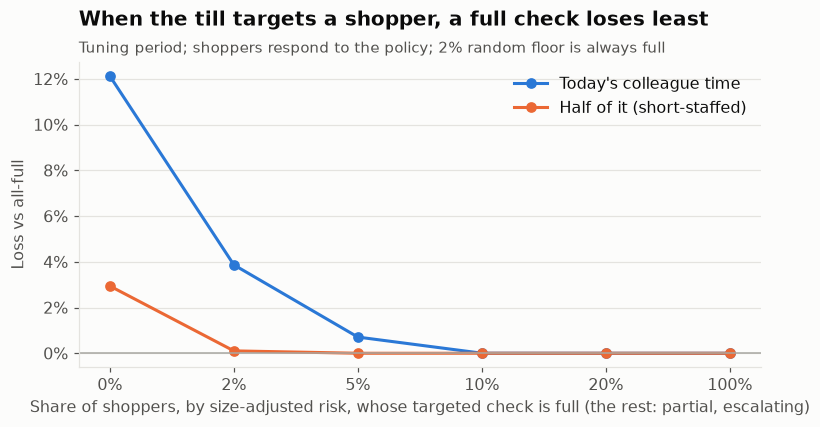

In [2]:
base = {s: tune[tune.colleague_time == s].set_index('full_share') for s in ('today', 'half')}
fig, ax = plt.subplots(figsize=(8, 3.6))
for s, colour, label in (('today', BLUE, "Today's colleague time"),
                         ('half', ORANGE, 'Half of it (short-staffed)')):
    d = base[s]
    rel = d.loss_remaining / d.loss_remaining.loc[1.0] - 1
    x = range(len(rel))
    ax.plot(x, rel.values, marker='o', color=colour, label=label)
ax.set_xticks(range(len(rel)), [f'{v:.0%}' for v in rel.index])
ax.yaxis.set_major_formatter(pct())
ax.axhline(0, color=GREY, lw=1)
ax.set_xlabel('Share of shoppers, by size-adjusted risk, whose targeted check is full '
              '(the rest: partial, escalating)')
ax.set_ylabel('Loss vs all-full')
ax.legend(frameon=False)
ax.set_title('When the till targets a shopper, a full check loses least')
subtitle(ax, 'Tuning period; shoppers respond to the policy; 2% random floor is always full')
save(fig, '26_partial_vs_full')
fig

**Reading it.**

- **Turning targeted checks into partial checks always adds loss.** At today's colleague time,
  making every risk-based check partial leaves about 12% more loss than making them all full; it
  only stops getting worse once at least the top tenth of shoppers by risk get full checks, and
  those are where all the targeted checks go anyway.
- **It holds when short-staffed**, when cheaper partial checks might have been expected to win by
  covering more shoppers.
- **It holds if partial checks were more careful** (finding 97% of picked mistakes rather than
  53%) or checked 25% of the basket instead of 20% (checked separately while building v1.4).
- **Why:** items taken on purpose are usually concealed, and a partial check rarely reaches them;
  it escalates only if the sample happens to contain a slip. A full check of a shopper the model
  has already picked out goes straight to what matters.

## Findings

| # | Finding | Implication |
|---|---|---|
| 1 | Modelled properly (20% of the basket, escalating), today's checks recover about 43% more than 3 fixed items did, for about 18% more colleague time | Today is a stronger baseline; the headline is restated against it |
| 2 | Against it, the recommended policy still cuts loss by about a fifth and stops 58% fewer honest shoppers, with the same colleague time | The conclusion holds |
| 3 | For targeted checks, full beats partial at every mix, on a full and a half-staffed shift, and with more careful partial checks | **v1.4**: the till asks for a full check when it targets; partial checks stay a cheap random courtesy check only if a store wants one |
| 4 | Training labels and the loss estimate use full checks only; an escalated partial check is excluded because the basket was chosen by what the sample found | Unchanged design, now explicit |

## 3. How big should a partial check be?

A bigger sample finds more per check but takes longer, so at the same colleague time fewer
shoppers can be checked: fewer honest shoppers stopped, but less deterrence. Every rule below is
run with today's random checks (2% full, and as many partial checks as today's colleague time
allows), on the tuning period, against shoppers who respond. Candidates: a fixed 3 or 5 items;
one share for every basket (10%–75%, at least 2 items); and a share by basket size (up to 10
items / 11–30 / over 30, each 10%, 20%, 30% or 50%), 74 rules in all.

How much a partial check deters a would-be thief has never been measured, so three assumptions
are tested: thieves fear any check alike; a partial check deters half as much as a full one; or
it deters in proportion to the share of the basket it covers.

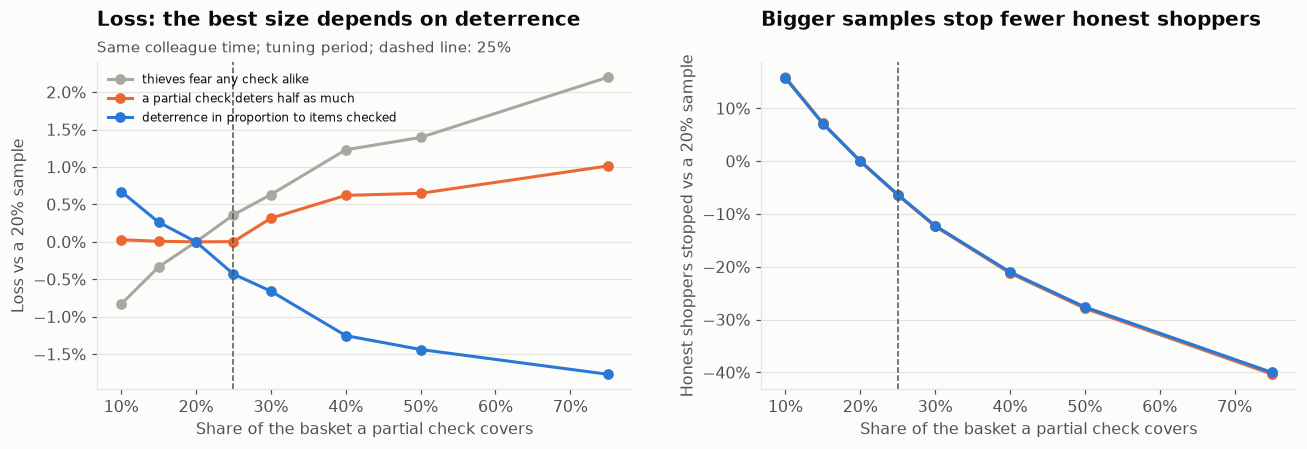

In [3]:
st = pd.read_csv('../results/sample_size_tuning.csv', index_col=0)
rule = json.load(open('../results/sample_size_rule.json'))
single = st[st.index.str.endswith('every basket')].copy()
single['share'] = single.index.str.extract(r'(\d+)%', expand=False).astype(int).values / 100
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
colours = {'thieves fear any check alike': GREY, 'a partial check deters half as much': ORANGE,
           'deterrence in proportion to items checked': BLUE}
for label, c in colours.items():
    d = single[single.deterrence == label].sort_values('share')
    axes[0].plot(d.share, d['loss vs 20% rule'], marker='o', color=c, label=label)
    axes[1].plot(d.share, d['honest stops vs 20% rule'], marker='o', color=c, label=label)
for ax in axes:
    ax.xaxis.set_major_formatter(pct())
    ax.axvline(0.25, color=TEXT_2, lw=1, ls='--')
    ax.set_xlabel('Share of the basket a partial check covers')
from matplotlib.ticker import PercentFormatter
axes[0].yaxis.set_major_formatter(PercentFormatter(1, decimals=1))
axes[1].yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
axes[0].set_ylabel('Loss vs a 20% sample')
axes[1].set_ylabel('Honest shoppers stopped vs a 20% sample')
axes[0].legend(frameon=False, fontsize=8, loc='upper left')
axes[0].set_title('Loss: the best size depends on deterrence')
axes[1].set_title('Bigger samples stop fewer honest shoppers')
fig.tight_layout(w_pad=3)
subtitle(axes[0], 'Same colleague time; tuning period; dashed line: 25%')
save(fig, '27_partial_sample_size')
fig

In [4]:
worst = st.groupby(level=0).regret.max().sort_values()
print('Worst case across the three assumptions, loss vs the best rule for that assumption:')
print(worst.head(8).map('{:.2%}'.format).to_string())
pd.read_csv('../results/sample_size.csv', index_col=0)[
    ['deterrence', 'partial check rate', 'items per partial check', 'loss vs 20% rule',
     'recovered vs 20% rule', 'honest stops vs 20% rule']].round(3)

Worst case across the three assumptions, loss vs the best rule for that assumption:
rule
by size 30%/30%/20%    1.31%
by size 50%/30%/20%    1.32%
25% of every basket    1.36%
by size 50%/20%/30%    1.37%
by size 30%/20%/30%    1.38%
by size 20%/30%/20%    1.38%
by size 10%/30%/20%    1.38%
by size 10%/30%/30%    1.41%


,deterrence,partial check rate,items per partial check,loss vs 20% rule,recovered vs 20% rule,honest stops vs 20% rule
rule,,,,,,
10% of every basket,thieves fear any check alike,0.119,2.824,-0.008,-0.153,0.163
3 items (before v1.4),thieves fear any check alike,0.122,2.811,-0.005,-0.236,0.184
20% of every basket,thieves fear any check alike,0.100,4.506,0.000,0.000,0.000
25% of every basket,thieves fear any check alike,0.092,5.396,0.002,0.051,-0.065
by size 30%/30%/20%,thieves fear any check alike,0.094,5.294,0.002,0.020,-0.052
30% of every basket,thieves fear any check alike,0.085,6.378,0.003,0.092,-0.125
by size 50%/30%/20%,thieves fear any check alike,0.092,5.564,0.003,0.024,-0.067
50% of every basket,thieves fear any check alike,0.066,9.979,0.010,0.179,-0.282
25% of every basket,a partial check deters half as much,0.092,5.396,-0.001,0.049,-0.065


**Reading it.**

- **There is no single optimum without knowing how thieves see a partial check.** If they fear
  any check alike, small samples win (10%: more checks, so more deterrence). If they know a quick
  sample rarely reaches hidden items, large samples win (50–75%). Either way loss moves by only
  1–2% across sensible sizes at the same colleague time.
- **25% of every basket is the robust choice**: under every assumption its loss is within 1.4% of
  the best rule for that assumption. Against today's 20% it leaves loss unchanged (within ±0.3% on
  the test period), recovers about 5% more and stops about 6% fewer honest shoppers, at the same
  colleague time, because slightly fewer, slightly bigger checks are made.
- **Size bands do not help.** The best rule by basket size (30% up to 30 items, 20% above) is
  0.05 points better in the worst case than 25% for every basket: no difference worth
  explaining to colleagues. The minimum of 2 items already looks after small baskets.
- **It does not change the targeted-check finding**: with the chosen sample size, a partial check
  for targeted shoppers still loses to a full one.
- **What would settle it:** a store trial arm with 25% and one with 10%, measuring how often
  shoppers who would steal are deterred. Until then, 25%.

## Findings (section 3)

| # | Finding | Implication |
|---|---|---|
| 5 | The best partial sample size depends on how much a partial check deters, which has never been measured: 10% if thieves fear any check alike, 50–75% if they know a sample rarely reaches hidden items; loss moves by only 1–2% either way | Choose a size that is safe under every assumption, and measure deterrence in the trial |
| 6 | 25% of every basket is within 1.4% of the best under every assumption; against 20% it leaves loss unchanged, recovers about 5% more and stops about 6% fewer honest shoppers | **Partial checks: 25% of the basket, at least 2 items** |
| 7 | Sample size by basket size gains nothing worth the complexity | One share for every basket |